In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib

import sys
import json
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import *
import copy

sys.path.insert(0, "..")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from numeric_method.numeric_method import solve_navier_stokes
from modeling.data import geometry_to_mtx

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

In [67]:
with open("../../data/cases/cylinder.json", "r") as f:
    case_nm = json.load(f)

dx = dy = 0.02

height_phys = 0.41
width_phys = 2.2
inflow = 0.3
density = 1
viscosity = 0.001

viscosity = viscosity / density

beta = 0

height_px = int(height_phys / dx)
width_px = int(width_phys / dx)

# dy = height_phys / height_px
# dx = width_phys / width_px

cylinder_y = int((0.2 * height_px) / height_phys)
cylinder_x = int((0.2 * width_px) / width_phys)
cylinder_r = int((0.05 * height_px) / height_phys)

case_nm["width"] = width_px
case_nm["height"] = height_px
case_nm["dx"] = dx
case_nm["dy"] = dy
case_nm["density"] = density
case_nm["viscosity"] = viscosity
case_nm["beta"] = beta

C = 10
case_nm["time_step"] = 0.1 #np.max([dy, dx]) * C / inflow

L = 0

for gi in range(len(case_nm["geometry"])):
    if case_nm["geometry"][gi]["type"] == "inflow":
        case_nm["geometry"][gi]["vel"]["x"] = inflow
        L = case_nm["geometry"][gi]["size"]["height"] * dy
        break

    if case_nm["geometry"][gi]["type"] == "cylinder":
        case_nm["geometry"][gi]["pos"]["x"] = cylinder_x
        case_nm["geometry"][gi]["pos"]["y"] = cylinder_y
        case_nm["geometry"][gi]["size"] = cylinder_r

display(case_nm)

{'width': 110,
 'height': 20,
 'dx': 0.02,
 'dy': 0.02,
 'iterations': 500,
 'time_step': 0.1,
 'density': 1,
 'viscosity': 0.001,
 'beta': 0,
 'geometry': [{'type': 'wall',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': 1}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': -1},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': -1}},
  {'type': 'outflow',
   'pos': {'x': -1, 'y': 0},
   'size': {'width': 1, 'height': -1},
   'dir': {'x': -1, 'y': 0}},
  {'type': 'cylinder', 'pos': {'x': 10, 'y': 9}, 'size': 2},
  {'type': 'inflow',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': 1, 'height': -1},
   'vel': {'x': 0.3, 'y': 0}}]}

	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 500/500 [00:20<00:00, 24.99it/s]


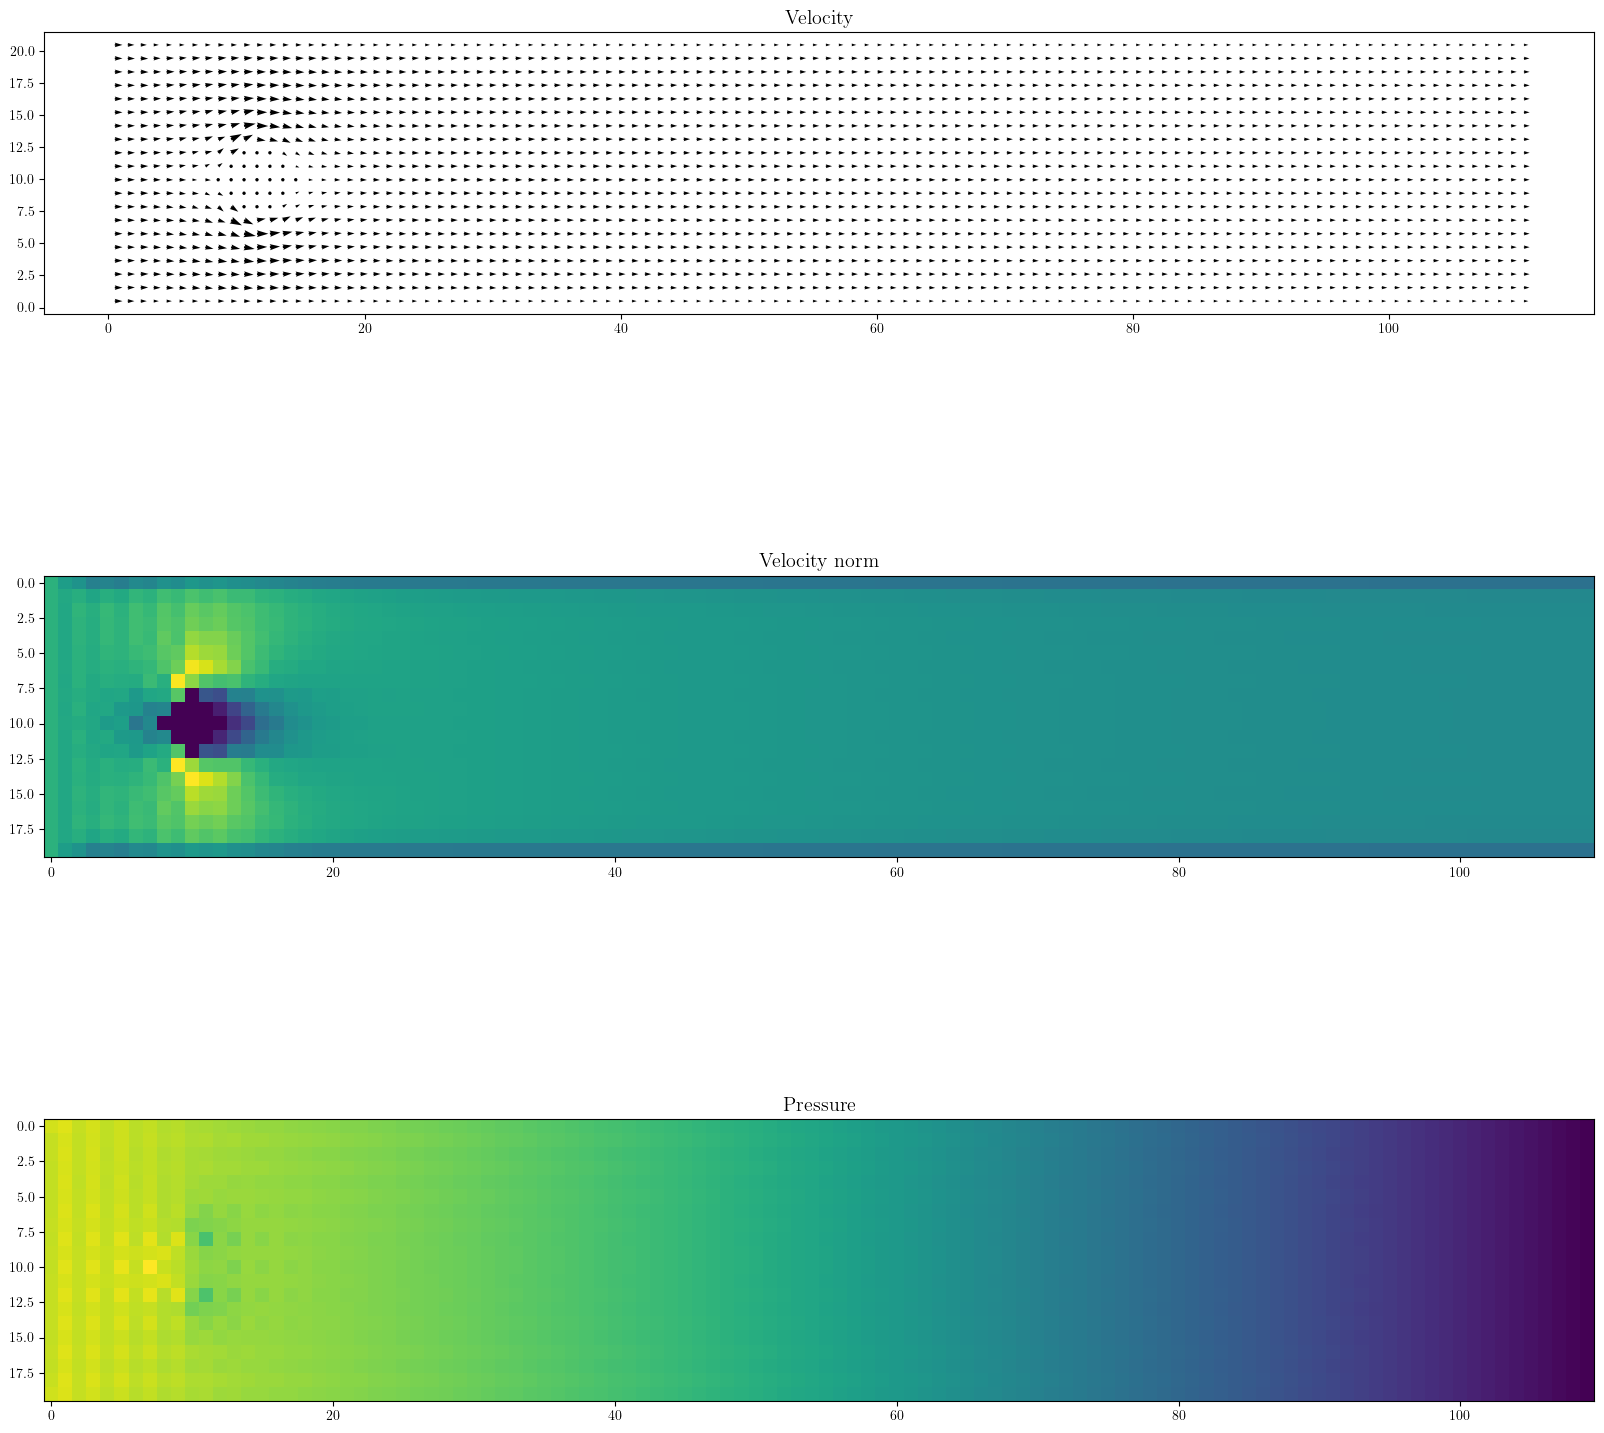

In [68]:
u, p, u_star, div_u_star, phi = solve_navier_stokes(
    case_nm["width"],
    # 370,
    case_nm["height"],
    dx,
    dy,
    int(case_nm["iterations"]),
    case_nm["time_step"],
    case_nm["density"],
    case_nm["viscosity"],
    case_nm["beta"],
    case_nm["geometry"],
    dynamic_time_step=True,
    implicit_laplacian=True,
    return_div_u_star=True,
    method_type="numeric"
)

# u = [u[i][1:-1, 1:-1, :] for i in range(len(u))]
# p = [p[i][1:-1, 1:-1] for i in range(len(p))]

# u = [u[i][:, 300:364, :] for i in range(len(u))]
# p = [p[i][:, 300:364] for i in range(len(p))]

# u = [u[i][:, :64, :] for i in range(len(u))]
# p = [p[i][:, :64] for i in range(len(p))]

u = u[-1]
p = p[-1]

_, _, _, _, _, _, boundary = geometry_to_mtx(case_nm["geometry"], width_px, height_px)

fig, ax = plt.subplots(3, 1, figsize=(20, 20))
ax = ax.flatten()
plot_velocity(ax[0], u[:, :, 0], u[:, :, 1], scale=0.5)
ax[0].set_title("Velocity")

nm_norm = np.linalg.norm(np.stack(u[::-1, :]), axis=-1)

ax[1].imshow(nm_norm)
ax[1].set_title("Velocity norm")

ax[2].imshow(p[::-1, :])
ax[2].set_title("Pressure")

plt.show()

## Pressure difference

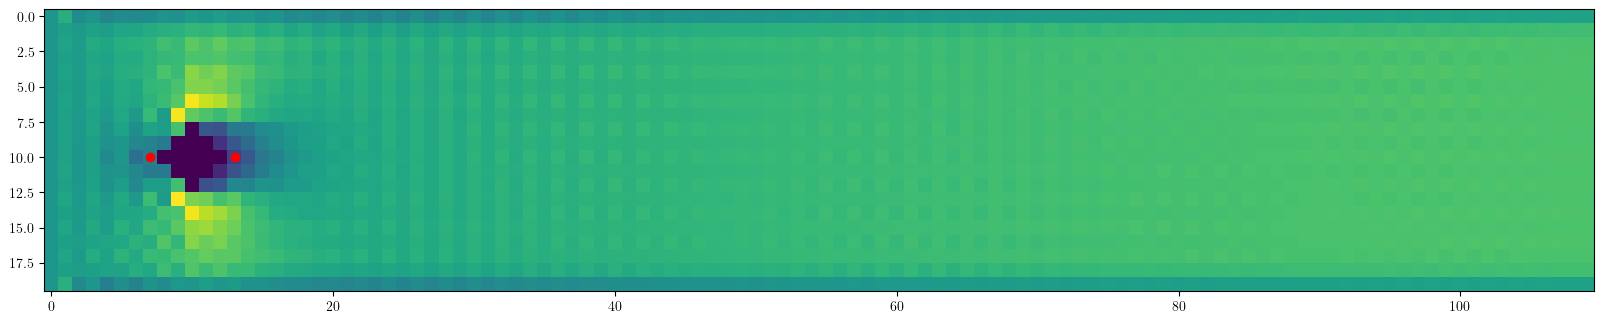

p_diff = -0.7069605153087561


In [66]:
a1 = [0.15, 0.2]
a2 = [0.25, 0.2]

a1[0] = int(np.floor(a1[0] / dx))
a1[1] = int(np.floor(a1[1] / dx))

a2[0] = int(np.ceil(a2[0] / dx))
a2[1] = int(np.ceil(a2[1] / dx))

fig, ax = plt.subplots(1, 1, figsize=(20, 5))
plt.imshow(nm_norm)
plt.scatter(a1[0], a1[1], color="red")
plt.scatter(a2[0], a2[1], color="red")
plt.show()

p_diff = p[a1[1], a1[0]] - p[a2[1], a2[0]]
print(f"p_diff = {p_diff}")